# Design Guide : Folded cascode
TODO : add opti pour noise, noise is calculated but not optimized
TODO : 
    add loop pour stability ? 
        Sizer L cascoce pour repousser le fp2
        Et si ça suffit pas ?

## Import libs

In [1]:
import numpy as np
import scipy.constants as sc
import catppuccin
import matplotlib.pyplot as plt
from pygmid import Lookup as lk
pmos4 = lk('../../lookup_table/035/pmos4.mat')
nmos4 = lk('../../lookup_table/035/nmos4.mat')
#pmos4 = lk('../../lookup_table/040/pmos_T40N.mat')
#nmos4 = lk('../../lookup_table/040/nmos_T40N.mat')
import sys; sys.path.append('../..')
import adri
from scipy.interpolate import interp1d
def interp1(x, y, value):
    # Interpolation function
    # Perform cubic interpolation using interp1d
    f = interp1d(x, y, kind='cubic')
    return f(value)


## STEP 1 : Specs

In [2]:
s = {
    'fu1'       : 0.1e6,
    'vod_noise' : 90e-6,
    'VDD' : 2.7,
    'VCM' : 1.35,
    'V_SWING_P2P_DIFF' : 0,
    'cload' : 10e-12,
}
d = {
    'gamma': 0.8,
    'Lcas': 0,
    'gm_IDcas': 0,
    'cself': 0,
    'gm_ID1': 0,
    'fp2' : 0,
}

## STEP 2 : Sizing the output branch

### Compute minimum GM_ID of output branch with output common mode min/max
Increasing gm_id, increase the total size of the MOS, reducing bandwidth
 $\frac {gm} {id} = \frac {2}{V_{ov}} $

In [3]:
kappa = 0.7

VDD = s['VDD']
VCM = s['VCM']
V_SWING_P2P_DIFF = s['V_SWING_P2P_DIFF']
VOUT_CM_HIGH = VCM+V_SWING_P2P_DIFF/2
VOUT_CM_LOW = VCM-V_SWING_P2P_DIFF/2
VDS_MOS = VOUT_CM_LOW/2
print('2 MOS pour', VOUT_CM_LOW)
gm_id = 2/(VDS_MOS)
print('gm_id > ', gm_id)
print(VDS_MOS)

2 MOS pour 1.35
gm_id >  2.962962962962963
0.675


### STEP 2.1 : Choose GM_ID output cascode

In [4]:
d['gm_IDcas'] = np.array([15])
print('On prend gm_IDcas =', d['gm_IDcas'])

On prend gm_IDcas = [15]


### STEP 2.2 : Compute Gain L0, with Lcascode sweep

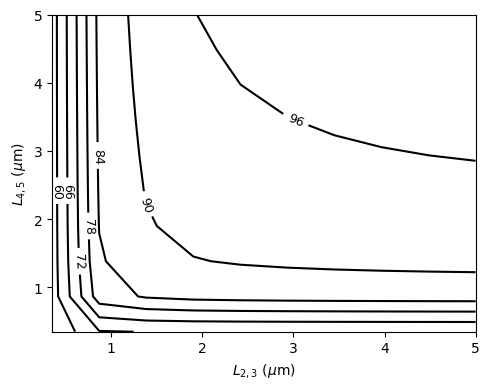

In [5]:
#Set L sweep for plot 
L = np.linspace(0.35, 5, 10)

#Compute gain param
gm_gds2 = nmos4.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = L, VDS = VDS_MOS, VSB = 0)
gm_gds3 = nmos4.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = L, VDS = VCM-VDS_MOS, VSB = VDS_MOS)
gm_gds4 = pmos4.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = L, VDS = VCM-VDS_MOS, VSB = VDS_MOS)
gm_gds5 = pmos4.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = L, VDS = VDS_MOS, VSB = 0)

L0 = np.zeros((len(L), len(L)))
#Copute L0 for range of Lcascode
for i in range(len(L)):
    L0[i, :] = kappa / (1/((1+gm_gds5)*gm_gds4) + 1/((1+1/3*gm_gds2[i])*gm_gds3[i]))
L0 = 20*np.log10(L0)
# Plotting
fig, ax = plt.subplots(figsize=(5, 4))
C = ax.contour(L, L, L0, colors='k', levels=8)
ax.clabel(C, fmt='%d', fontsize=9)
ax.set_xlabel(r'$L_{2,3}$ ($\mu$m)')
ax.set_ylabel(r'$L_{4,5}$ ($\mu$m)')
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams.update({"axes.grid": True})
plt.tight_layout()
plt.show()

### STEP 2.3 :  Choose L cascode

In [6]:
#Choose length
d['Lcas'] = np.array([2])
print('On prend L_cascode =', d['Lcas'])

gm_gds2 = nmos4.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS = VDS_MOS, VSB = 0)
gm_gds3 = nmos4.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS = VCM-VDS_MOS, VSB = VDS_MOS)
gm_gds4 = pmos4.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS = VCM-VDS_MOS, VSB = VDS_MOS)
gm_gds5 = pmos4.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS = VDS_MOS, VSB = 0)
L0 = kappa / (1/((1+gm_gds5)*gm_gds4) + 1/((1+1/3*gm_gds2)*gm_gds3))
L0 = 20*np.log10(L0)
adri.cool_print(L0)

On prend L_cascode = [2]
L0 = np.float64(92.23045594142648)


### STEP 2.4 :  Compute 2nd pole with casocde sizing
Aim for FP1 / FU1 == 4 for 75° phase margin => Best for settling

In [7]:

gmb_gm3 =   nmos4.lookup('GMB_GM', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS =  VCM-VDS_MOS, VSB = VDS_MOS)
gm_css3 =   nmos4.lookup('GM_CSS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS =  VCM-VDS_MOS, VSB = VDS_MOS)
cdd_css3 =  nmos4.lookup('CDD_CSS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS =  VCM-VDS_MOS, VSB = VDS_MOS)
cdd_w3  =   nmos4.lookup('CDD_CSS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS =  VCM-VDS_MOS, VSB = VDS_MOS)
cdd_w2  =   nmos4.lookup('CDD_CSS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS = VDS_MOS, VSB = 0) 

# Nondominant pole frequency
d['fp2'] = 1 / (2 * np.pi) * gm_css3 * (1 + gmb_gm3) / (1 + 2 * cdd_css3 * 2 * (cdd_w2 / cdd_w3))
print(f'Nondominant pole frequency: {d['fp2'] * 1e-9:.3f} GHz')
#print("FP2 / FU1 == 4 for 75° phase margin and fatest settling")
adri.cool_print(d['fp2'] / s['fu1'])

Nondominant pole frequency: 0.047 GHz
d['fp2'] / s['fu1'] = np.float64(473.0367726268062)


## Step 3 : sizing input diff pair

### Choose L diff pair L1

In [8]:
d['L1'] = 0.35
print('On prend L1 =', d['L1'])

On prend L1 = 0.35


### Self loading loop

In [9]:
d['gm_ID1'] = np.array([15])
#d['gm_IDcas'] = np.array([15])
#d['Lcas'] = np.array([1])
#d['L1'] = 0.35

m1,m2,m3,m4,m5,p = adri.folded_cascode(nmos4, pmos4, s, d)

#adri.print_design_summary(s, d,m1,m2,m3,m4,m5,p)

cself = np.zeros(10)
for i in range(len(cself)):
    d['cself'] = cself[i]
    m1,m2,m3,m4,m5,p = adri.folded_cascode(nmos4, pmos4, s, d)
    if i + 1 < len(cself):
        cself[i + 1] = p['cself'].item()
    # adri.cool_print(m1['ID'])
    # adri.cool_print(m1['W'])
adri.print_design_summary(s, d,m1,m2,m3,m4,m5,p)

In [10]:
# Extraction pour les MOS (W est déjà en unité correcte)
mos_data = [('M1', m1), ('M2', m2), ('M3', m3), ('M4', m4), ('M5', m5)]

for name, mos in mos_data:
    # On récupère les valeurs
    w_raw = mos['W']
    l_raw = mos['L']
    
    # On force la conversion en float scalaire propre
    # .flatten()[0] marche pour les arrays, float() marche pour les floats
    w_val = float(w_raw.flatten()[0]) if hasattr(w_raw, 'flatten') else float(w_raw)
    l_val = float(l_raw.flatten()[0]) if hasattr(l_raw, 'flatten') else float(l_raw)
    
    print(f"{name}_W {w_val:.3f}u")
    print(f"{name}_L {l_val:.2f}u")

# Extraction correcte de la valeur scalaire
valeur_ibias = m1['ID'].flatten()[0] *1e6
cload = s['cload']*1e12
# Application du formatage avec 'f' (pour le suffixe)
print(f"ibias {valeur_ibias:.3f}u")
print(f"cload {cload:.3f}p")

M1_W 0.601u
M1_L 0.35u
M2_W 2.077u
M2_L 2.00u
M3_W 1.039u
M3_L 2.00u
M4_W 3.027u
M4_L 2.00u
M5_W 3.027u
M5_L 2.00u
ibias 0.433u
cload 10.000p


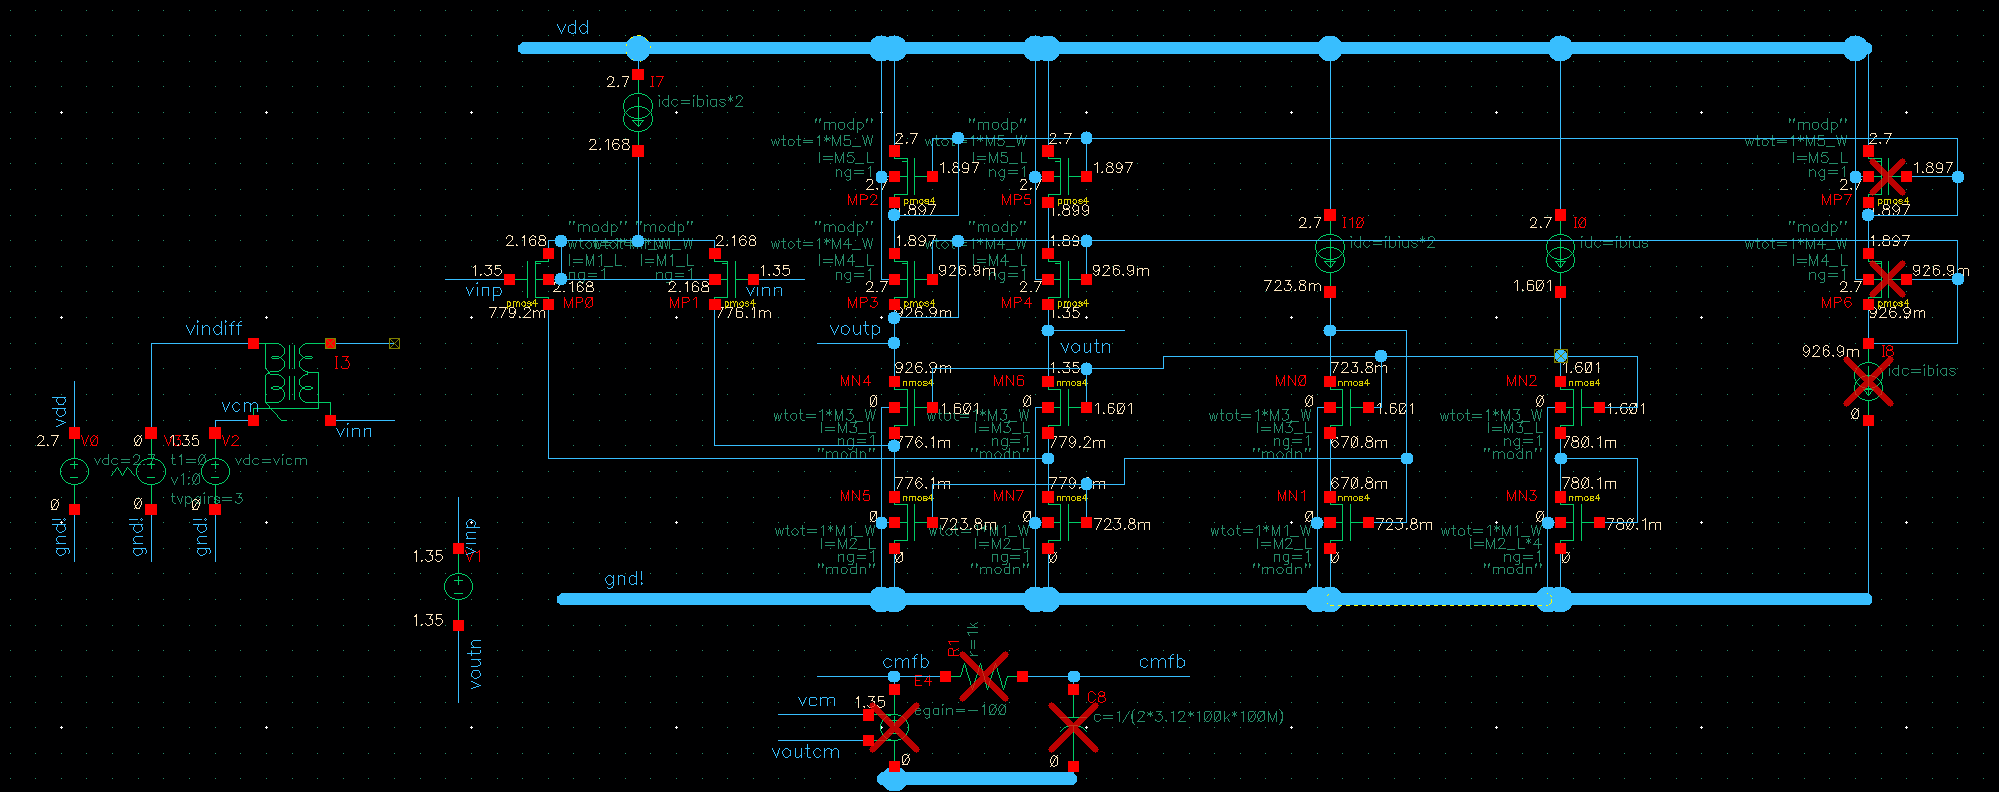  
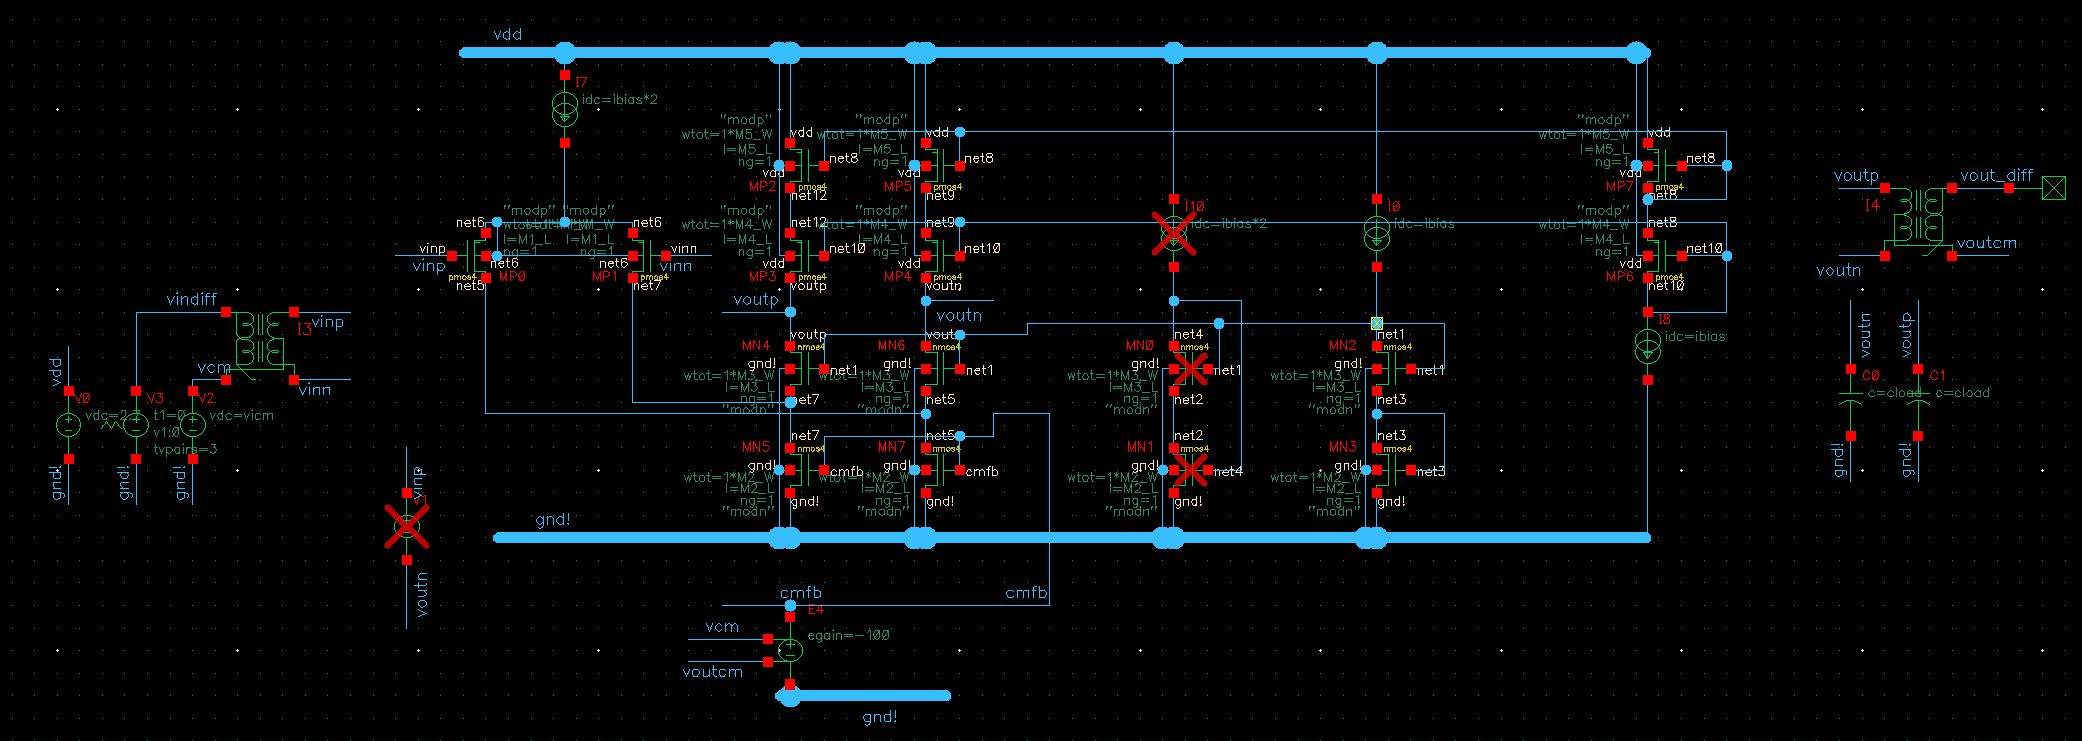

# All in one cell

In [11]:
# #Design Spec 
# s = {
#     'fu1'       : 1e6,
#     'vod_noise' : 90e-6,
#     'VDD' : 2.7,
#     'VCM' : 1.35,
#     'V_SWING_P2P_DIFF' : 1.8,
#     'cload' : 50e-12,
# }
# # Constants for another design
# d = {
#     'gamma': 0.8,
#     'Lcas': 0,
#     'gm_IDcas': 0,
#     'cself': 0,
#     'gm_ID1': 0,
#     'fp2' : 0,
# }
# d['gm_ID1'] = np.array([12])
# d['gm_IDcas'] = np.array([15])
# d['Lcas'] = np.array([1])
# d['L1'] = 0.35

# m1,m2,m3,m4,m5,p = adri.folded_cascode(nmos4, pmos4, s, d)

# #adri.print_design_summary(s, d,m1,m2,m3,m4,m5,p)

# cself = np.zeros(10)
# for i in range(len(cself)):
#     d['cself'] = cself[i]
#     m1,m2,m3,m4,m5,p = adri.folded_cascode(nmos4, pmos4, s, d)
#     if i + 1 < len(cself):
#         cself[i + 1] = p['cself'].item()
#     # adri.cool_print(m1['ID'])
#     # adri.cool_print(m1['W'])
# adri.print_design_summary(s, d,m1,m2,m3,m4,m5,p)